### Estimate the wave speed using PINNs (inverse problem). 
The goal of the inverse problem is to estimate the wave speed $c(x,y)$ from data of the wave field $p(x,y,t)$ that satisfies the wave equation,
$$\frac{\partial^2 p}{\partial x^2} + \frac{\partial^2 p}{\partial y^2} - \frac{1}{c^2} \frac{\partial^2 p}{\partial t^2} = 0.$$

The inference of $c(x,y)$ will be based on:
- The observed data 
- Physics via the underlying PDE

As in the previous notebook (PINN_forward.ipynb), we will use physics-informed neural networks for the task.

By Samuel A. Verburg, saveri@dtu.dk. This notebook was inspired by [Moseley 2020] and [Rasht-Behesht 2022] (see a list of references at the end).


You can open the notebook in Colab by clicking the link. 
<a href="https://colab.research.google.com/github/RAMshades/AcousticsML/blob/main/5_5_PINNs_inverse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Uncomment the following lines before running the script in Colab:

In [ ]:
# !git clone https://github.com/RAMshades/AcousticsML.git
# %cd AcousticsML

In [1]:
import numpy as np
import torch
import torch.nn as nn
from tqdm import tqdm
from PINNs_util.PINNs_fdiff import solver
from PINNs_util.PINNs_aux import FCN,\
                        xyt_tensor,\
                        pde_residual,\
                        update_lambda,\
                        rand_colloc

from PINNs_util.PINNs_plots import plot_train_log,\
                        plot_field,\
                        plot_data,\
                        plot_estimation,\
                        plot_speed,\
                        plot_speed_log

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

#### Problem setup

We define a domain and simulate the reference field. In this case, we consider a wave speed with an ellipse-shaped inhomogeneity, where the speed is twice as much as in the rest of the domain. We also change the initial condition, so that 'source' corresponds to three pulses aligned with the x-axis. 

100%|██████████| 125/125 [00:00<00:00, 5504.91it/s]


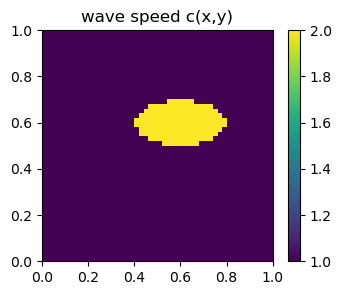

100%|██████████| 253/253 [00:00<00:00, 3555.52it/s]


In [2]:
# define domain
L = 5
T = 1.5
c0 = 3

# scaling
T = T*c0/L
L = L/L
c0 = 1

# wave speed
def c_ref(xx, yy, tensor=False):
    if tensor:
        c = torch.ones_like(xx, device=device)
    else:
        c = np.ones_like(xx)
    # ellipse inhomogeneity
    x_ellip, y_ellip = 0.6, 0.6
    a, b = 0.2, 0.1
    ind_ellip = ((xx-x_ellip)/a)**2 + ((yy-y_ellip)/b)**2 <= 1
    c[ind_ellip] = 2
    return c

# initial condition
def I(xx, yy):
    I = np.zeros_like(xx)
    # 4 pulses
    gpulse_std = 5e-2
    r_pulse = np.array([0, 0.2])
    for _ in range(3):
        r_pulse[0] += 0.25
        I += np.exp(-0.5*( ((xx-r_pulse[0])/gpulse_std)**2 +\
                           ((yy-r_pulse[1])/gpulse_std)**2 ))
    return I

# simulation
Lx, Ly = L, L
Nx, Ny = 50, 50
dt = -1

# solve
p_ref, xx, yy, t, dt = solver(I, c_ref, Lx, Ly, Nx, Ny, dt, T)

# we need tensors
xy = np.hstack((np.reshape(xx,(-1,1)), np.reshape(yy,(-1,1))))
r_ref = xyt_tensor(xy, t, device)
xy_ref = torch.tensor(xy, device=device)
n_T = t.shape[0]
n_L = xx.shape[0]

# plot wave speed 
plot_speed(c_ref(xx, yy), L)

# plot high res reference field (it might take a few seconds)
p_plot,_,_,_,_ = solver(I, c_ref, Lx, Ly, int(Nx*2), int(Ny*2), -1, T)
ani = plot_field(p_plot, L, 'wave field (high res plot)')
ani

In [3]:
# Initial condition
n_ini = 15
t_ini = t[0:n_ini]
r_ini = xyt_tensor(xy, t_ini, device)
p_ini = p_ref[:,:,:n_ini].reshape(-1,1)
p_ini = torch.tensor(p_ini, device=device)

#### Generate data

The data will be the pressure field on a number of points randomly sampled from the reference field (black triangles in the left figure). The observed data, called `p_data`, is shown in the right figure. 
In contrast with the previous notebook, we do not know the initial condition, which will have to be inferred from the data, together with the rest of $p(x,y,t)$ and $c(x,y)$.

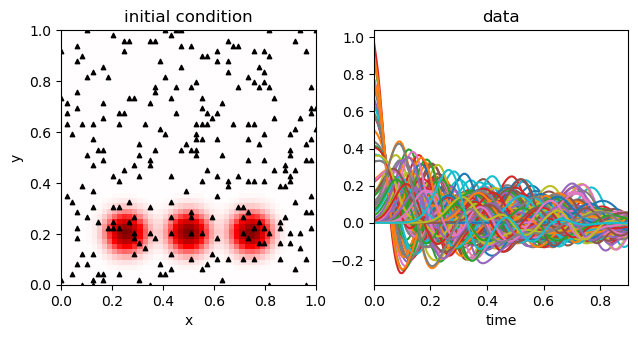

In [4]:
np.random.seed(1)
n_data = 250
i_data = np.random.choice(n_L**2, n_data, replace=False)

x_data = xx.reshape(-1,1)[i_data]
y_data = yy.reshape(-1,1)[i_data]
xy_data = np.column_stack((x_data, y_data))
r_data = xyt_tensor(xy_data, t, device)
p_data = p_ref.reshape(-1,n_T)[i_data,:]

# Plot data
plot_data(p_ref, p_data, x_data, y_data, L, T)

p_data = torch.tensor(p_data, device=device)

### PINNs
For the inverse problem, we define two NNs: `model_p` with inputs $(x,y,t)$ which learns the wave field $p(x,y,t)$, and `model_c` with inputs $(x,y)$, which learn the wave speed $c(x,y)$. The number of layers, hidden units, etc. don't need to be the same for the two NNs (`model_c` could actually be smaller as the function $c$ is only two-dimensional).

In [5]:
n_in = 3
n_out = 1
n_ffeatures = 64
n_hidden = 64
n_layers = 3
n_lamb_update = 100
n_colloc = int(1e4)

# n_causal = int(2e3)
n_causal = int(1e0)
n_epochs = int(n_causal*(n_T-1))
n_warmpup = int(1e4)

lamb = [1, 1, 1]

model_p = FCN(n_in, n_out, n_ffeatures, n_hidden, n_layers)
model_p = model_p.to(device)
model_c = FCN(n_in-1, n_out, n_ffeatures, n_hidden, n_layers)
model_c = model_c.to(device)

optimiser_p = torch.optim.Adam(model_p.parameters(), lr=1e-4)
optimiser_c = torch.optim.Adam(model_c.parameters(), lr=1e-4)
mse_loss = nn.MSELoss()

loss_data_hist = []
loss_ini_hist = []
loss_pde_hist = []
lamb_data_hist = []
lamb_ini_hist = []
lamb_pde_hist = []
c_hist = []


It can be useful to initialise `model_c` with an initial guess what the speed might look like. Here we pre-train the network with a constant (homogeneous) velocity of value $c_0=1$.

In [6]:
for i in tqdm(range(n_warmpup)):
    optimiser_c.zero_grad()
    r_colloc = rand_colloc(n_colloc, L, 0, device)
    c = model_c(r_colloc[:,:2])
    loss = mse_loss(c, c0*torch.ones_like(c))
    loss.backward()
    optimiser_c.step()
print('Loss model_c:', loss.item())

100%|██████████| 10000/10000 [00:20<00:00, 492.06it/s]

Loss model_c: 2.0291554392315447e-06


Once `model_c` is on the 'right path', we can train both networks jointly. The connecting point between the two networks is the wave equation loss term `pde_res` since we need both, the wave speed and the wave field, to compute it. 

In [7]:
print('Traning PINN...')
i_causal = 0

for i in tqdm(range(n_epochs)):
    optimiser_p.zero_grad()
    optimiser_c.zero_grad()

    # initial condition loss
    p = model_p(r_ini)
    loss_ini = mse_loss(p, p_ini)

    if i % n_causal == 0:
        i_causal += 1
    
    # data loss
    p = model_p(r_data)
    p = p.view(-1, n_T)
    loss_data = mse_loss(p[:,:i_causal], p_data[:,:i_causal])

    # pde loss
    r_colloc = rand_colloc(n_colloc, L, t[i_causal], device)
    p = model_p(r_colloc)
    c = model_c(r_colloc[:,:2])
    pde_res = pde_residual(p, r_colloc, c)
    loss_pde = mse_loss(pde_res, torch.zeros_like(p))

    loss_lst = [loss_ini, loss_data, loss_pde]

    # get gradients and update lambda
    if i % n_lamb_update == 0: 
        lamb = update_lambda(model_p, loss_lst, lamb, 0.9)

    # total loss
    loss = loss_ini +\
            loss_data*lamb[1]/lamb[0] +\
            loss_pde*lamb[2]/lamb[0]

    # backpropagate
    loss.backward()
    optimiser_p.step()
    optimiser_c.step()

    # log
    loss_ini_hist.append(loss_data.item())
    loss_data_hist.append(loss_data.item())
    loss_pde_hist.append(loss_pde.item())
    lamb_ini_hist.append(lamb[0].item())
    lamb_data_hist.append(lamb[1].item())
    lamb_pde_hist.append(lamb[2].item())

    # print loss
    if i % 5000 == 4999:
        print('[%5d] loss: %.3f*1e-3' %
        (i + 1, loss.item()*1e3))
        with torch.no_grad():
            c_est = model_c(xy_ref)
            c_est = c_est.detach().cpu().numpy()
            c_hist.append(c_est)

Traning PINN...


100%|██████████| 125/125 [00:02<00:00, 42.70it/s]


Save the trained models.

In [8]:
# # save the trained model and loss log
# path = "./PINNs_util/trained_models/inverse/"
# torch.save(model_p.state_dict(), path+"model_p.pt")
# torch.save(model_c.state_dict(), path+"model_c.pt")

# loss = [loss_ini_hist, loss_data_hist, loss_pde_hist]
# lamb = [lamb_ini_hist, lamb_data_hist, lamb_pde_hist]

# torch.save(loss, path+"loss.pt")
# torch.save(lamb, path+"lamb.pt")
# torch.save(c_hist, path+"c_hist.pt")

Load the trained models.

In [13]:
path = "./PINNs_util/trained_models/inverse/"
model_p.load_state_dict(torch.load(path+"model_p.pt", weights_only=True, map_location=torch.device('cpu')))
model_p.eval()
model_p.to(device)
model_c.load_state_dict(torch.load(path+"model_c.pt", weights_only=True, map_location=torch.device('cpu')))
model_c.eval()
model_c.to(device)

loss = torch.load(path+"loss.pt", weights_only=True, map_location=torch.device('cpu'))
lamb = torch.load(path+"lamb.pt", weights_only=True, map_location=torch.device('cpu'))
c_hist = torch.load(path+"c_hist.pt", weights_only=False, map_location=torch.device('cpu'))

Plot the loss and lambda. 

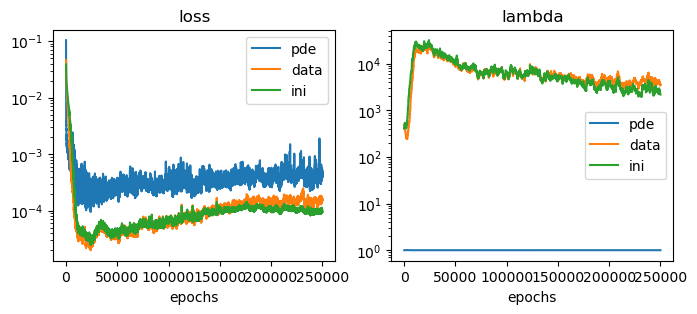

In [ ]:
label = ['ini', 'data', 'pde']
plot_train_log(loss, lamb, label)

Plot the estimated wave field.

In [ ]:
# Plot reference and estimation
p_est = model_p(r_ref)
p_est = p_est.cpu().detach().numpy()
ani = plot_estimation(p_ref, p_est, L)
ani

Plot the wave speed as `model_c` was being trained. 

In [ ]:
ani = plot_speed_log(c_hist, c_ref(xx,yy), L)
ani

### References

[Moseley 2020] Moseley, B., Markham, A., & Nissen-Meyer, T. (2020). Solving the wave equation with physics-informed deep learning. arXiv preprint arXiv:2006.11894. https://doi.org/10.48550/arXiv.2006.11894

[Rasht-Behesht 2022] Rasht‐Behesht, M., Huber, C., Shukla, K., & Karniadakis, G. E. (2022). Physics‐informed neural networks (PINNs) for wave propagation and full waveform inversions. Journal of Geophysical Research: Solid Earth, 127(5), e2021JB023120. https://doi.org/10.1029/2021JB023120

[Wang 2023] Wang, S., Sankaran, S., Wang, H., & Perdikaris, P. (2023). An expert's guide to training physics-informed neural networks. arXiv preprint arXiv:2308.08468. https://doi.org/10.48550/arXiv.2308.08468 

[Langtangen 2016] Langtangen, H. P., & Pedersen, G. K. (2016). Scaling of differential equations (p. 138). Springer Nature.

[Langtangen 2017] Langtangen, H. P., & Linge, S. (2017). Finite difference computing with PDEs: a modern software approach. Springer Nature.

[Tancik 2020] Tancik, M., Srinivasan, P., Mildenhall, B., Fridovich-Keil, S., Raghavan, N., Singhal, U., ... & Ng, R. (2020). Fourier features let networks learn high frequency functions in low dimensional domains. Advances in neural information processing systems, 33, 7537-7547. https://doi.org/10.48550/arXiv.2006.10739 

[Wang 2021b] Wang, S., Wang, H., & Perdikaris, P. (2021). On the eigenvector bias of Fourier feature networks: From regression to solving multi-scale PDEs with physics-informed neural networks. Computer Methods in Applied Mechanics and Engineering, 384, 113938. https://doi.org/10.1016/j.cma.2021.113938 

[Sitzmann 2020] Sitzmann, V., Martel, J., Bergman, A., Lindell, D., & Wetzstein, G. (2020). Implicit neural representations with periodic activation functions. Advances in neural information processing systems, 33, 7462-7473. https://doi.org/10.48550/arXiv.2006.09661

[Wang 2021] Wang, S., Teng, Y., & Perdikaris, P. (2021). Understanding and mitigating gradient flow pathologies in physics-informed neural networks. SIAM Journal on Scientific Computing, 43(5), A3055-A3081. https://doi.org/10.1137/20M1318043

[Wang 2024] Wang, S., Sankaran, S., & Perdikaris, P. (2024). Respecting causality for training physics-informed neural networks. Computer Methods in Applied Mechanics and Engineering, 421, 116813. https://doi.org/10.1016/j.cma.2024.116813 

[Mattey 2022] Mattey, R., & Ghosh, S. (2022). A novel sequential method to train physics informed neural networks for Allen Cahn and Cahn Hilliard equations. Computer Methods in Applied Mechanics and Engineering, 390, 114474. https://doi.org/10.1016/j.cma.2021.114474